<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HancockDT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
Merged data shape: (763, 49)

Dataset Shape: (332, 6)

Class Distribution:
HPV
0    191
1    141
Name: count, dtype: int64

Training Patients: 215
Validation Patients: 50
Test Patients: 67

Original Predictors: 6
One-Hot Encoded Features: 19
Scaling: None - tree-based model

Training samples without SMOTE:
0    123
1     92
Name: count, dtype: int64

Decision Tree Model:
DecisionTreeClassifier(class_weight={0: np.float64(0.8739837398373984),
                                     1: np.float64(1.1684782608695652)},
                       random_state=42)
Tree depth: 22
Tree leaves: 88

Validation Results
---------------------------
ROC_AUC             : 0.5944
PR_AUC              : 0.4845
Accuracy            : 0.6200
BA                  : 0.5936
Precision           : 0.5625
Recall              : 0.4286
F1                  : 0.4865
TN                  : 22
FP                  : 7
FN                  : 12
TP                  : 9

Classification Report

           

,Model,Checkpoint_Selection,N_Train,N_Validation,N_Test,Original_Predictor_Count,Encoded_Feature_Count,Tree_Depth,Tree_Leaves,Validation_ROC_AUC,...,Test_PR_AUC,Test_Accuracy,Test_BA,Test_Precision,Test_Recall,Test_F1,Test_TN,Test_FP,Test_FN,Test_TP
0,Decision Tree,Single_Fitted_Tree,215,50,67,6,19,22,88,0.594417,...,0.55929,0.686567,0.665293,0.652174,0.535714,0.588235,31,8,13,15


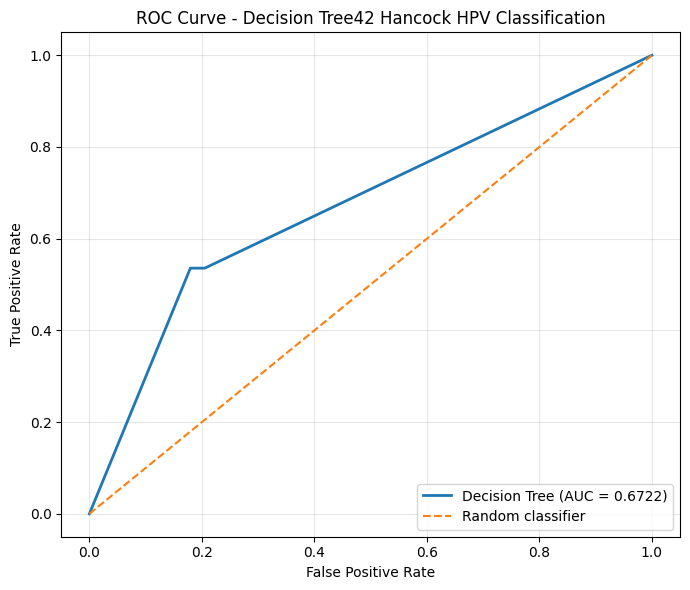

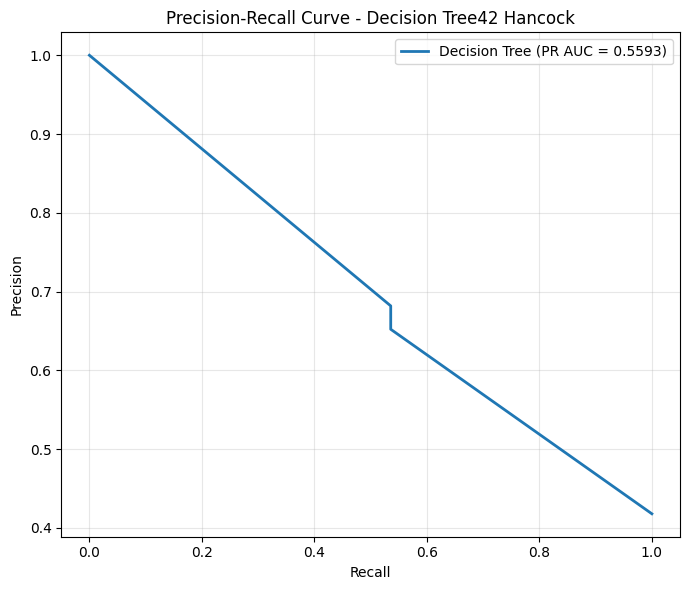


DECISION TREE42_HANCOCK SUMMARY
Model: Decision Tree
Predictors: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
Original Input Features: 6
One-Hot Encoded Features: 19
Scaling: None - tree-based model
Class Weights: Training labels
SMOTE: No
Preprocessing: Train-only
Imputation: Train-derived mode/median
Encoding: Train-fitted OneHotEncoder
Split: 65% train / 15% validation / 20% test
Training Patients: 215
Validation Patients: 50
Test Patients: 67
Seed: 42

Final Test Results
---------------------------
ROC_AUC             : 0.6722
PR_AUC              : 0.5593
Accuracy            : 0.6866
BA                  : 0.6653
Precision           : 0.6522
Recall              : 0.5357
F1                  : 0.5882
TN                  : 31
FP                  : 8
FN                  : 13
TP                  : 15

Metrics saved:
  /content/drive/MyDrive/DT_results/DT_results.csv
  /content/drive/MyDrive/DT_results/DT_test_predictions

In [1]:

# ============================================================
# DT42_Hancock
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES AND SET RANDOM SEEDS
# ============================================================

import os, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    balanced_accuracy_score, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, roc_curve,
    precision_recall_curve
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# ============================================================
# 2. READ AND MERGE DATA
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

with open('/content/drive/MyDrive/clinical_data.json') as f:
    clinical = pd.DataFrame(json.load(f))

with open('/content/drive/MyDrive/pathological_data.json') as f:
    pathology = pd.DataFrame(json.load(f))

df = clinical.merge(pathology, on='patient_id', how='inner')
print("Merged data shape:", df.shape)

# ============================================================
# 3. HPV LABELS
# ============================================================

target_col = 'hpv_association_p16'

df = df[
    df[target_col].astype(str).str.strip().str.lower()
    .isin(['positive', 'negative'])
].copy()

df['HPV'] = (
    df[target_col].astype(str).str.strip().str.lower()
    .map({'negative': 0, 'positive': 1})
)

# ============================================================
# 4. BUILD MODELLING DATASET
#    Six predictors used by ANN/GPT-2
# ============================================================

feature_cols = [
    'age_at_initial_diagnosis',
    'sex',
    'smoking_status',
    'primary_tumor_site',
    'primarily_metastasis',
    'pN_stage'
]

# Handle common alternative names for pN stage
if 'pN_stage' not in df.columns:
    alternatives = [
        'pathological_N_stage', 'pathologic_N_stage',
        'pathological_n_stage', 'pN'
    ]
    matched = next(
        (col for col in alternatives if col in df.columns), None
    )
    if matched:
        df = df.rename(columns={matched: 'pN_stage'})
        print(f"Using '{matched}' as 'pN_stage'.")

missing_cols = [c for c in feature_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required predictors: {missing_cols}")

df_model = df[
    ['patient_id'] + feature_cols + ['HPV']
].copy()

df_model = df_model.dropna(subset=['HPV'])
df_model['HPV'] = df_model['HPV'].astype(int)
df_model = df_model.drop_duplicates(
    subset=['patient_id'], keep='first'
).copy()

numeric_features = ['age_at_initial_diagnosis']
categorical_features = [
    'sex', 'smoking_status', 'primary_tumor_site',
    'primarily_metastasis', 'pN_stage'
]

for col in categorical_features:
    df_model[col] = df_model[col].apply(
        lambda x: str(x).strip() if pd.notna(x) else np.nan
    )

df_model['age_at_initial_diagnosis'] = pd.to_numeric(
    df_model['age_at_initial_diagnosis'], errors='coerce'
)

X = df_model[feature_cols].copy()
y = df_model['HPV'].copy()
patient_ids = df_model['patient_id'].copy()

print("\nDataset Shape:", X.shape)
print("\nClass Distribution:")
print(y.value_counts().sort_index())

# ============================================================
# 5. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
#    65% TRAIN / 15% VALIDATION / 20% TEST
# ============================================================

X_train_val, X_test, y_train_val, y_test, ids_train_val, ids_test = (
    train_test_split(
        X, y, patient_ids, test_size=0.20,
        random_state=SEED, stratify=y
    )
)

X_train, X_val, y_train, y_val, ids_train, ids_val = (
    train_test_split(
        X_train_val, y_train_val, ids_train_val,
        test_size=0.1875, random_state=SEED,
        stratify=y_train_val
    )
)

print("\nTraining Patients:", len(y_train))
print("Validation Patients:", len(y_val))
print("Test Patients:", len(y_test))

assert set(ids_train).isdisjoint(set(ids_val))
assert set(ids_train).isdisjoint(set(ids_test))
assert set(ids_val).isdisjoint(set(ids_test))

# ============================================================
# 6. MISSING VALUES AND ONE-HOT ENCODING
#    Fit preprocessing on TRAIN ONLY
# ============================================================

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Decision Trees do not require feature scaling
if hasattr(X_train_processed, 'toarray'):
    X_train_processed = X_train_processed.toarray()
    X_val_processed = X_val_processed.toarray()
    X_test_processed = X_test_processed.toarray()

X_train_processed = np.asarray(X_train_processed)
X_val_processed = np.asarray(X_val_processed)
X_test_processed = np.asarray(X_test_processed)

y_train_np = y_train.to_numpy(dtype=int)
y_val_np = y_val.to_numpy(dtype=int)
y_test_np = y_test.to_numpy(dtype=int)

n_features = X_train_processed.shape[1]

print("\nOriginal Predictors:", len(feature_cols))
print("One-Hot Encoded Features:", n_features)
print("Scaling: None - tree-based model")
print("\nTraining samples without SMOTE:")
print(pd.Series(y_train_np).value_counts().sort_index())

# ============================================================
# 7. DECISION TREE MODEL
# ============================================================

class_counts = np.bincount(y_train_np, minlength=2)
class_weights = len(y_train_np) / (2 * class_counts)
class_weight_dict = {
    i: class_weights[i] for i in range(2)
}

model = DecisionTreeClassifier(
    class_weight=class_weight_dict,
    random_state=SEED
)

model.fit(X_train_processed, y_train_np)

print("\nDecision Tree Model:")
print(model)
print("Tree depth:", model.get_depth())
print("Tree leaves:", model.get_n_leaves())

# ============================================================
# 8. METRIC HELPER
# ============================================================

def calculate_metrics(y_true, probabilities, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities).astype(float)
    predicted = (probabilities >= threshold).astype(int)

    metrics = {
        'ROC_AUC': np.nan,
        'PR_AUC': np.nan,
        'Accuracy': accuracy_score(y_true, predicted),
        'BA': balanced_accuracy_score(y_true, predicted),
        'Precision': precision_score(
            y_true, predicted, zero_division=0
        ),
        'Recall': recall_score(
            y_true, predicted, zero_division=0
        ),
        'F1': f1_score(y_true, predicted, zero_division=0)
    }

    if len(np.unique(y_true)) == 2:
        metrics['ROC_AUC'] = roc_auc_score(
            y_true, probabilities
        )
        metrics['PR_AUC'] = average_precision_score(
            y_true, probabilities
        )

    tn, fp, fn, tp = confusion_matrix(
        y_true, predicted, labels=[0, 1]
    ).ravel()

    metrics.update({
        'TN': int(tn), 'FP': int(fp),
        'FN': int(fn), 'TP': int(tp)
    })
    return metrics

# ============================================================
# 9. VALIDATION
#    Test data is not used for model selection
# ============================================================

val_prob = model.predict_proba(X_val_processed)[:, 1]
val_metrics = calculate_metrics(y_val_np, val_prob)

print("\nValidation Results")
print("---------------------------")
for name, value in val_metrics.items():
    print(f"{name:20s}: {value:.4f}" if
          isinstance(value, (float, np.floating))
          else f"{name:20s}: {value}")

# ============================================================
# 10. FINAL TEST SET EVALUATION
# ============================================================

test_pred = model.predict(X_test_processed)
test_prob = model.predict_proba(X_test_processed)[:, 1]
test_metrics = calculate_metrics(y_test_np, test_prob)

print("\nClassification Report\n")
print(classification_report(
    y_test_np, test_pred, digits=4, zero_division=0
))

cm = confusion_matrix(y_test_np, test_pred)
print("Confusion Matrix")
print(cm)

print("\nTest Metrics")
print("---------------------------")
for name, value in test_metrics.items():
    print(f"{name:20s}: {value:.4f}" if
          isinstance(value, (float, np.floating))
          else f"{name:20s}: {value}")

# ============================================================
# 11. SAVE TEST METRICS AND PREDICTIONS
# ============================================================

output_dir = '/content/drive/MyDrive/DT_results'
os.makedirs(output_dir, exist_ok=True)

results_df = pd.DataFrame([{
    'Model': 'Decision Tree',
    'Checkpoint_Selection': 'Single_Fitted_Tree',
    'N_Train': len(y_train),
    'N_Validation': len(y_val),
    'N_Test': len(y_test),
    'Original_Predictor_Count': len(feature_cols),
    'Encoded_Feature_Count': n_features,
    'Tree_Depth': model.get_depth(),
    'Tree_Leaves': model.get_n_leaves(),
    **{f'Validation_{k}': v for k, v in val_metrics.items()},
    **{f'Test_{k}': v for k, v in test_metrics.items()}
}])

results_path = os.path.join(output_dir, 'DT_results.csv')
results_df.to_csv(results_path, index=False)

predictions_df = pd.DataFrame({
    'patient_id': ids_test.to_numpy(),
    'y_true': y_test_np,
    'y_prob_HPV_positive': test_prob,
    'y_pred_threshold_0.5': test_pred
})

predictions_path = os.path.join(
    output_dir, 'DT_test_predictions.csv'
)
predictions_df.to_csv(predictions_path, index=False)

print("\nSaved test metrics to:")
print(results_path)
print("\nSaved test predictions to:")
print(predictions_path)
print("\nTest-set results:")
display(results_df)

# ============================================================
# 12. ROC / AUC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(y_test_np, test_prob)
auc_curve = roc_auc_score(y_test_np, test_prob)

plt.figure(figsize=(7, 6))
plt.plot(
    fpr, tpr, linewidth=2,
    label=f'Decision Tree (AUC = {auc_curve:.4f})'
)
plt.plot(
    [0, 1], [0, 1], linestyle='--',
    linewidth=1.5, label='Random classifier'
)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree42 Hancock HPV Classification')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 13. PRECISION-RECALL CURVE
# ============================================================

precision, recall, _ = precision_recall_curve(
    y_test_np, test_prob
)
pr_auc_curve = average_precision_score(y_test_np, test_prob)

plt.figure(figsize=(7, 6))
plt.plot(
    recall, precision, linewidth=2,
    label=f'Decision Tree (PR AUC = {pr_auc_curve:.4f})'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Decision Tree42 Hancock')
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 14. MODEL SUMMARY
# ============================================================

print("\n====================================")
print("DECISION TREE42_HANCOCK SUMMARY")
print("====================================")
print("Model: Decision Tree")
print("Predictors:", feature_cols)
print("Original Input Features:", len(feature_cols))
print("One-Hot Encoded Features:", n_features)
print("Scaling: None - tree-based model")
print("Class Weights: Training labels")
print("SMOTE: No")
print("Preprocessing: Train-only")
print("Imputation: Train-derived mode/median")
print("Encoding: Train-fitted OneHotEncoder")
print("Split: 65% train / 15% validation / 20% test")
print("Training Patients:", len(y_train))
print("Validation Patients:", len(y_val))
print("Test Patients:", len(y_test))
print("Seed:", SEED)

print("\nFinal Test Results")
print("---------------------------")
for name, value in test_metrics.items():
    print(f"{name:20s}: {value:.4f}" if
          isinstance(value, (float, np.floating))
          else f"{name:20s}: {value}")

print("\nMetrics saved:")
print(" ", results_path)
print(" ", predictions_path)
print("\nAnalysis Complete.")
